# 01 · Los datos

Antes de comparar modelos conviene saber **qué videos tenemos y de dónde salen**. Este notebook recorre el camino completo, desde la muestra de YouTube-8M hasta lo que ve la web:

1. **YouTube-8M** nos da una muestra de videos, cada uno con un id seudónimo (`pid`) y sus etiquetas.
2. Un servicio de Google traduce cada `pid` a su `youtube_id` real.
3. Con la **YouTube Data API** traemos título, descripción, tags y miniatura (lo llamamos *hidratar*).
4. Descargamos las **miniaturas**, que usamos para las representaciones de imagen.

Todo eso lo hace `python3 recolect.py`. Aquí solo leemos lo que dejó en `data/`; no se recalcula nada.

In [1]:
import sys
from pathlib import Path

# Los notebooks viven en notebooks/, pero los datos (data/) y el código (analysis/, recolect/)
# están en la raíz del repo. Así funcionan abriéndolos desde cualquiera de las dos carpetas.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

In [2]:
import json
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analysis.metricas import DATA, cargar_vocabulario, categoria
from analysis.graficos import INK, MUTED, GRID, estilo, thumb, corto
from recolect.embedding import build_text   # la misma función que usan recolect.py y el servidor

estilo()

/Users/jabac/dev/mineria_youtube/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Del `pid` al video: cuántos sobreviven

`embeddings_consolidated.parquet` junta todo en una sola tabla: una fila por video de la muestra, con sus metadatos y una columna por representación. Partimos contando cuántos videos quedan en cada paso. Muchos videos de YT-8M (subidos antes de 2018) ya fueron borrados o pasaron a privados, y de esos no hay nada que rescatar.

In [3]:
df = pd.read_parquet(DATA / "embeddings_consolidated.parquet")

embudo = pd.Series({
    "Muestra de YT-8M": len(df),
    "Con youtube_id": df["youtube_id"].notna().sum(),
    "Siguen públicos (metadatos)": df["title"].notna().sum(),
    "Con miniatura": df["emb_image"].notna().sum(),
})
embudo.to_frame("videos")

,videos
Muestra de YT-8M,41393
Con youtube_id,37230
Siguen públicos (metadatos),34788
Con miniatura,34771


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


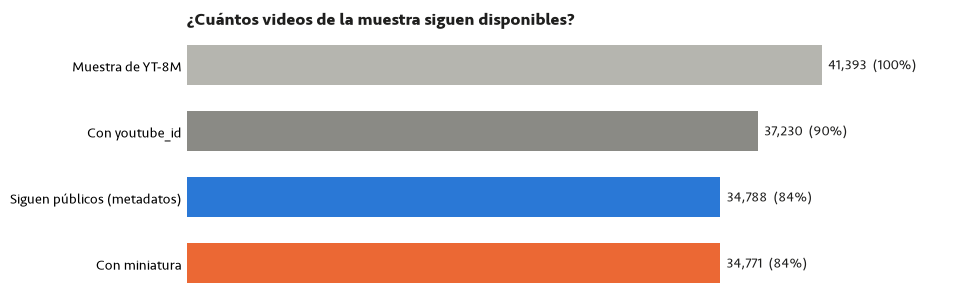

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.4))
y = np.arange(len(embudo))[::-1]
ax.barh(y, embudo.values, height=0.6, color=["#b5b5af", "#8a8a85", "#2a78d6", "#eb6834"])
for yy, n in zip(y, embudo.values):
    ax.text(n + embudo.max() * 0.01, yy, f"{n:,}  ({n / embudo.iloc[0]:.0%})", va="center", color=INK)
ax.set_yticks(y, embudo.index)
ax.set_xlim(0, embudo.max() * 1.22)
ax.set_title("¿Cuántos videos de la muestra siguen disponibles?", loc="left", fontweight="bold", color=INK)
ax.xaxis.set_visible(False)
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
plt.show()

De aquí en adelante trabajamos con los videos que siguen públicos (los que tienen título). Las comparaciones que mezclan texto e imagen usan los que además tienen miniatura, para que todas las representaciones se midan **sobre exactamente los mismos videos**.

## 2. Etiquetas y categorías de YouTube-8M

Cada video trae varias **etiquetas** del vocabulario de YT-8M: 3.806 entidades como *Video game*, *Guitar* o *Cooking*. Cada etiqueta pertenece a una **categoría** amplia (`Vertical1`: *Games*, *Arts & Entertainment*, *Autos & Vehicles*…).

Un video puede tener etiquetas de varias categorías, así que le asignamos **la categoría más repetida entre sus etiquetas**. Esa es la "verdad" contra la que evaluamos los mapas en los notebooks siguientes: si un espacio es bueno, los videos de la misma categoría deberían quedar cerca.

In [5]:
vocab = cargar_vocabulario()
vertical_de = dict(zip(vocab["Index"].astype(int), vocab["Vertical1"]))
nombre_de = dict(zip(vocab["Index"].astype(int), vocab["Name"]))

videos = df[df["title"].notna()].reset_index(drop=True)
videos["vertical"] = [categoria(l, vertical_de) for l in videos["labels"]]

n_labels = videos["labels"].map(len)
print(f"{len(vocab):,} etiquetas posibles en {vocab['Vertical1'].nunique()} categorías")
print(f"etiquetas por video: promedio {n_labels.mean():.1f}, mediana {n_labels.median():.0f}, máximo {n_labels.max()}")

3,806 etiquetas posibles en 25 categorías
etiquetas por video: promedio 3.0, mediana 3, máximo 16


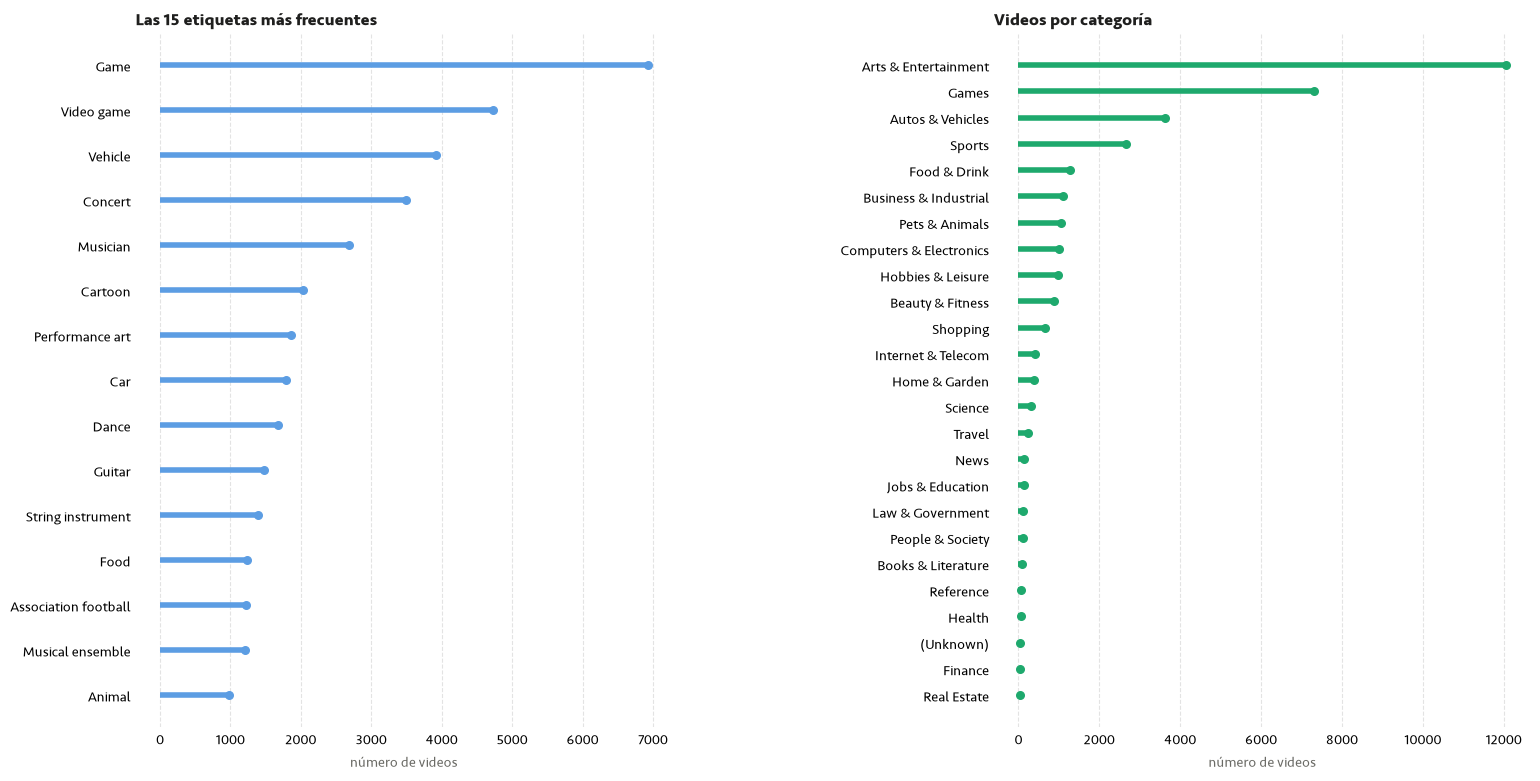

In [6]:
# (algunos ids de etiqueta no tienen nombre en el vocabulario publicado; esos se omiten)
top_etiquetas = (pd.Series([nombre_de[int(l)] for ls in videos["labels"] for l in ls if int(l) in nombre_de])
                 .value_counts().head(15).sort_values())
categorias = videos["vertical"].value_counts().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(18, 9), gridspec_kw={"wspace": 0.6})
for ax, serie, color, titulo in [
    (axes[0], top_etiquetas, "#5C9DE3", "Las 15 etiquetas más frecuentes"),
    (axes[1], categorias, "#1EA96D", "Videos por categoría"),
]:
    y = np.arange(len(serie))
    ax.hlines(y, 0, serie.values, color=color, lw=4)        # gráfico de "paletas": línea + punto
    ax.scatter(serie.values, y, color=color, s=30, zorder=3)
    ax.set_yticks(y, serie.index)
    ax.set_title(titulo, loc="left", fontweight="bold", color=INK)
    ax.set_xlabel("número de videos", color=MUTED)
    ax.grid(axis="x", ls="--", alpha=0.35)
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
plt.show()

Las categorías están muy desbalanceadas: *Games* y *Arts & Entertainment* se llevan buena parte de los videos. Por eso en las métricas siempre comparamos contra el **baseline de mayoría** (predecir siempre la categoría más común): un modelo que no lo supera no está aprendiendo nada.

## 3. El texto de cada video

El modelo de texto no recibe solo el título. Armamos un texto con **el título, hasta 15 tags y los primeros 600 caracteres de la descripción** (sin URLs). Es la misma función que usan `recolect.py` y el servidor, así que un video nuevo que llega por la web se representa igual que los de la muestra.

In [7]:
ejemplo = videos.sample(1, random_state=3).iloc[0]
print(f"https://www.youtube.com/watch?v={ejemplo.youtube_id}   ·   categoría: {ejemplo.vertical}")
print("etiquetas YT-8M:", ", ".join(nombre_de.get(int(l), f"#{l}") for l in ejemplo["labels"]))
print("\n--- texto que recibe el modelo ---\n")
print(build_text(ejemplo.to_dict()))

https://www.youtube.com/watch?v=miUUNqAM1eo   ·   categoría: Hobbies & Leisure
etiquetas YT-8M: Pet, Fishing, Fish, Recreational fishing, Rock fishing

--- texto que recibe el modelo ---

Fishing on the THUNDERBIRD
Tags: fishing, over night trip, White Seabass (Organism Classification), Yellow Tail (Brand), rock fishing, catalina island
FISHING IN THE THUNDER BIRD 2013 over night trip, fishing for yellow tail, white sea bass, and rock fish. Catalina island


## 4. Las miniaturas

Para las representaciones de imagen usamos la miniatura que YouTube muestra en los resultados (`data/thumbs/<youtube_id>.jpg`). Es lo primero que ve alguien antes de hacer clic, así que resume bastante del contenido… o del *clickbait*.

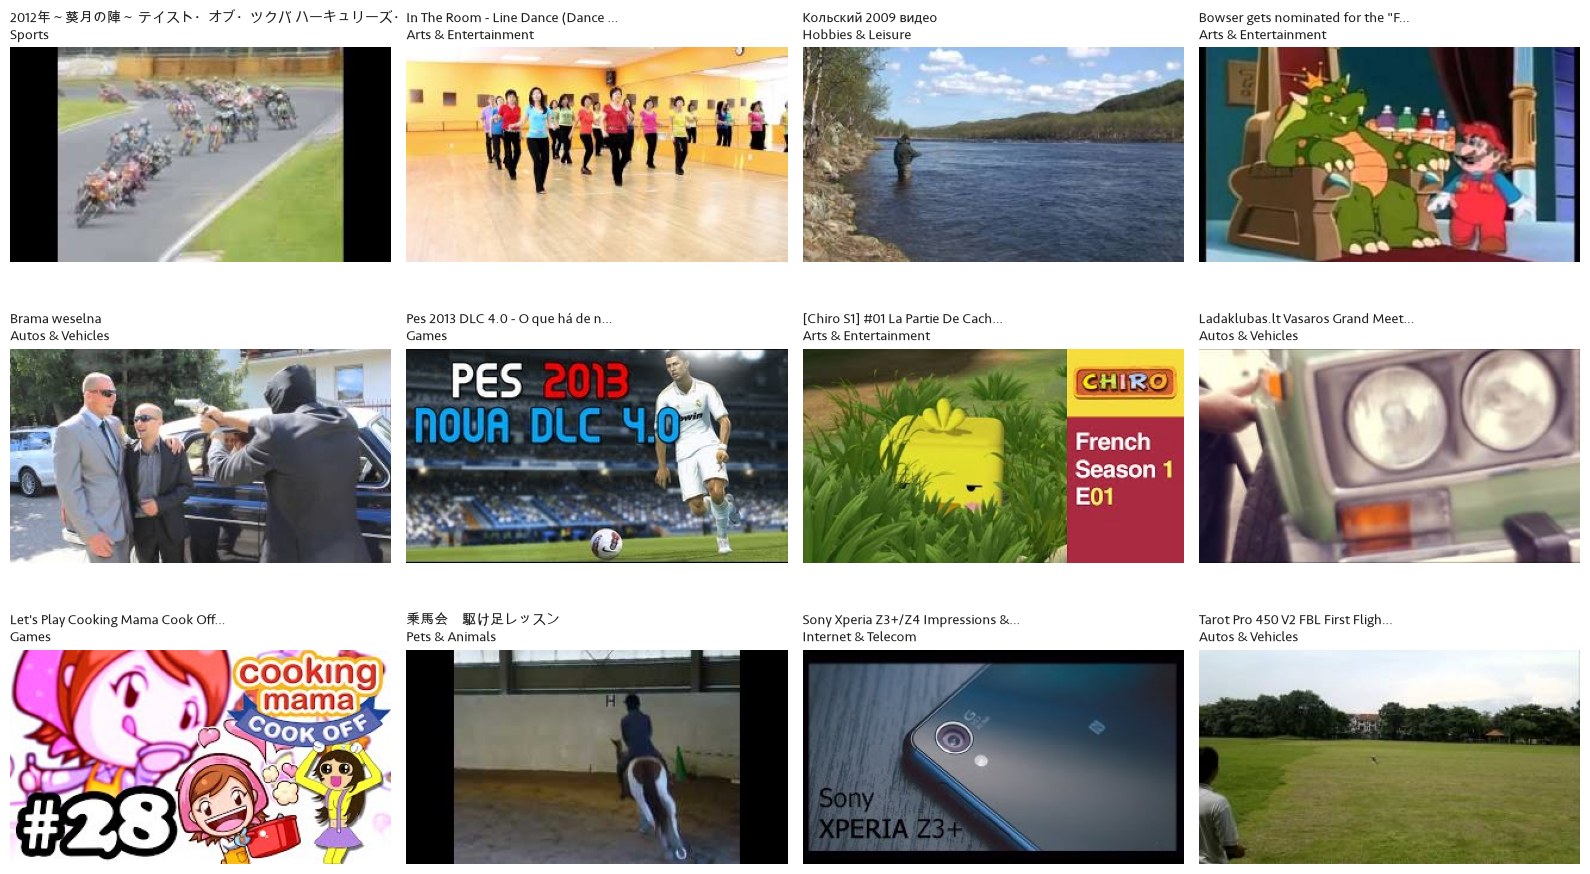

In [8]:
muestra = videos[videos["emb_image"].notna()].sample(12, random_state=11)

fig, axes = plt.subplots(3, 4, figsize=(16, 9.5))
for ax, (_, r) in zip(axes.flat, muestra.iterrows()):
    ax.imshow(thumb(r.youtube_id))
    ax.axis("off")
    ax.set_title(f"{corto(r.title, 32)}\n{r.vertical}", fontsize=10, color=INK, loc="left")
plt.tight_layout()
plt.show()

## 5. Videos que no son de YT-8M

La muestra de YT-8M es vieja. Para que el mapa de la web también tenga videos actuales, el catálogo suma dos fuentes más, guardadas en `data/webapp_catalog.sqlite3`:

- **`python3 recolect.py --modern`**: videos populares recientes y de canales semilla (también en `modern_videos.parquet`).
- **La web**: cada video que alguien consulta queda guardado con su embedding.

Estos videos **no tienen etiquetas de YT-8M**, así que no entran en las métricas; sí aparecen en el mapa.

In [9]:
with sqlite3.connect(DATA / "webapp_catalog.sqlite3") as db:
    filas = db.execute("SELECT metadata_json, received_at FROM received").fetchall()
recibidos = pd.DataFrame([json.loads(m) | {"received_at": t} for m, t in filas])

modernos = set(pd.read_parquet(DATA / "modern_videos.parquet", columns=["youtube_id"])["youtube_id"])
recibidos["origen"] = np.where(recibidos["youtube_id"].isin(modernos), "recolect --modern", "web")
recibidos["origen"].value_counts().to_frame("videos")

,videos
origen,
recolect --modern,1243
web,19


¿Cuánto cambia la época? Comparamos el año de publicación de los videos de YT-8M con el de los recibidos.

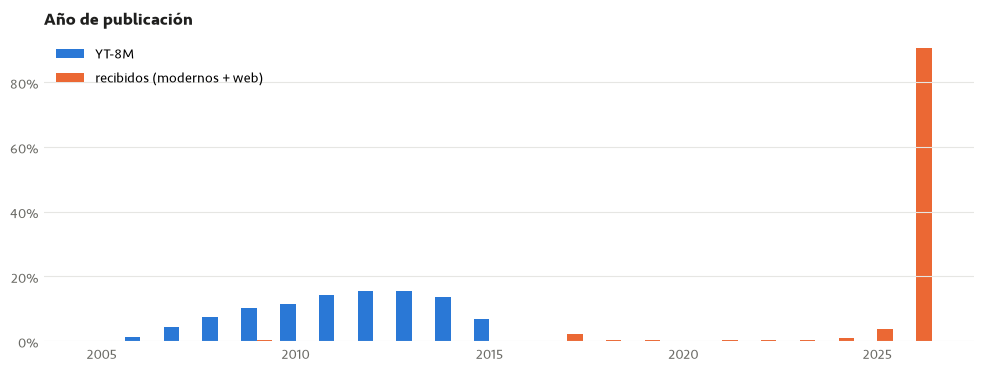

In [10]:
def años(fechas):
    return pd.to_datetime(fechas, utc=True, errors="coerce").dt.year.dropna().astype(int).value_counts(normalize=True)

hidratados = pd.read_parquet(DATA / "yt8m_hydrated.parquet", columns=["published_at"])
por_año = pd.DataFrame({"YT-8M": años(hidratados["published_at"]),
                        "recibidos": años(recibidos["published_at"])}).fillna(0).sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(por_año.index - 0.2, por_año["YT-8M"], width=0.4, color="#2a78d6", label="YT-8M")
ax.bar(por_año.index + 0.2, por_año["recibidos"], width=0.4, color="#eb6834", label="recibidos (modernos + web)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("Año de publicación", loc="left", fontweight="bold", color=INK)
ax.legend(frameon=False)
ax.grid(axis="y", color=GRID)
ax.tick_params(length=0, colors=MUTED)
for sp in ax.spines.values():
    sp.set_visible(False)
plt.show()

## Qué sigue

- **02** compara EmbeddingGemma con TF-IDF y MiniLM usando solo el texto.
- **03** suma la miniatura: texto, imagen, imagen + texto y fusión tardía en un mismo espacio.
- **04** etiqueta miniaturas sin entrenar nada (zero-shot), comparándolas con el vocabulario.
- **05** busca grupos en el mapa de la web con HDBSCAN y les pone nombre.